AS (Aortic Stenosis) ditandai penyempitan katup aorta sehingga aliran darah dari ventrikel kiri ke aorta terhambat. Pada PCG tampak murmur sistolik keras dengan puncak di mid-systole serta energi frekuensi dominan pada 100–200 Hz.
MR (Mitral Regurgitation) terjadi ketika katup mitral bocor sehingga darah kembali ke atrium kiri saat sistole. Ciri PCG-nya adalah murmur sistolik holosystolacic yang panjang dengan spektrum frekuensi melebar, menunjukkan energi baik pada frekuensi rendah maupun tinggi.
MS (Mitral Stenosis) merupakan penyempitan katup mitral yang menghambat aliran darah dari atrium ke ventrikel kiri. Pada PCG tampak opening snap (OS) setelah S2 dan murmur diastolik low-frequency berbentuk “rumbling” dengan dominasi frekuensi rendah (<120 Hz).
MVP (Mitral Valve Prolapse) terjadi ketika katup mitral menonjol ke atrium kiri saat sistole. PCG menampilkan “mid-systolic click” yang khas diikuti murmur sistolik pendek, menghasilkan pola unik yang sangat cocok untuk analisis wavelet.
N (Normal) menunjukkan PCG tanpa kelainan katup jantung, dengan suara S1 dan S2 yang jelas, tanpa murmur tambahan, serta pola spektrum frekuensi yang rapi, smooth, dan teratur.

In [2]:
import os
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, hilbert, welch, find_peaks
import pywt
from scipy.fft import rfft, rfftfreq
from IPython.display import Audio
plt.rcParams['figure.figsize'] = (10,4)


In [ ]:
# # Blok 2 - bandpass + wavelet denoising + resample util
# def bandpass_filter(sig, sr, low=20, high=500, order=4):
#     nyq = 0.5 * sr
#     lown = low/nyq
#     highn = high/nyq
#     b, a = butter(order, [lown := lown, highn], btype='band')
#     return filtfilt(b, a, sig)

# def wavelet_denoise(sig, wavelet='db8', level=None):
#     coeffs = pywt.wavedec(sig, wavelet, mode='symmetric')
#     if level is None:  # dwt level heuristic
#         level = min(len(coeffs)-1, 5)
#     sigma = (1/0.6745) * np.median(np.abs(coeffs[-level]))
#     uthresh = sigma * np.sqrt(2 * np.log(len(sig)))
#     denoised_coeffs = [pywt.threshold(c, value=uthresh, mode='soft') if i>0 else c for i,c in enumerate(coeffs)]
#     return pywt.waverec(denoised_coeffs, wavelet, mode='symmetric')

# def ensure_sr(sig, sr, target_sr=2000):
#     if sr == target_sr:
#         return sig, sr
#     sig_resampled = librosa.resample(sig, orig_sr=sr, target_sr=target_sr)
#     return sig_resampled, target_sr


In [3]:
# Blok 2 - bandpass + wavelet denoising + resample util
def bandpass_filter(sig, sr, low=20, high=500, order=4):
    nyq = 0.5 * sr
    lown = low/nyq
    highn = high/nyq

    print("=== BANDPASS FILTER ===")
    print(f"Sampling rate (sr)        : {sr}")
    print(f"Nyquist frequency (nyq)   : {nyq}")
    print(f"Low cutoff (normalized)   : {lown}")
    print(f"High cutoff (normalized)  : {highn}")
    print(f"Filter order              : {order}")

    b, a = butter(order, [lown := lown, highn], btype='band')

    print(f"Filter coefficients b     : {b}")
    print(f"Filter coefficients a     : {a}")

    filtered = filtfilt(b, a, sig)
    print(f"Output signal length      : {len(filtered)}\n")
    return filtered


def wavelet_denoise(sig, wavelet='db8', level=None):
    print("=== WAVELET DENOISING ===")
    print(f"Wavelet used              : {wavelet}")

    coeffs = pywt.wavedec(sig, wavelet, mode='symmetric')
    print(f"Total decomposition levels: {len(coeffs)-1}")

    if level is None:
        level = min(len(coeffs)-1, 5)
    print(f"Selected threshold level  : {level}")

    sigma = (1/0.6745) * np.median(np.abs(coeffs[-level]))
    print(f"Estimated noise sigma     : {sigma}")

    uthresh = sigma * np.sqrt(2 * np.log(len(sig)))
    print(f"Universal threshold       : {uthresh}")

    denoised_coeffs = []
    for i, c in enumerate(coeffs):
        if i > 0:
            c2 = pywt.threshold(c, value=uthresh, mode='soft')
            print(f"Coeff {i} | before: {np.mean(np.abs(c)):.6f}  after: {np.mean(np.abs(c2)):.6f}")
            denoised_coeffs.append(c2)
        else:
            denoised_coeffs.append(c)

    reconstructed = pywt.waverec(denoised_coeffs, wavelet, mode='symmetric')
    print(f"Reconstructed signal len  : {len(reconstructed)}\n")
    return reconstructed


def ensure_sr(sig, sr, target_sr=2000):
    print("=== RESAMPLING CHECK ===")
    print(f"Original SR               : {sr}")
    print(f"Target SR                 : {target_sr}")

    if sr == target_sr:
        print("SR sama → tidak di-resample.\n")
        return sig, sr

    sig_resampled = librosa.resample(sig, orig_sr=sr, target_sr=target_sr)
    print(f"Resampled signal length   : {len(sig_resampled)}\n")
    return sig_resampled, target_sr


In [ ]:
# # Blok 3 - envelope & simple S1/S2 detection
# def envelope_hilbert(sig):
#     analytic = hilbert(sig)
#     env = np.abs(analytic)
#     return env

# def detect_beats_from_envelope(env, sr, distance_ms=250, prominence=0.2):
#     distance = int(sr * distance_ms / 1000)
#     peaks, props = find_peaks(env, distance=distance, prominence=prominence*np.max(env))
#     peak_times = peaks / sr
#     return peaks, peak_times, props

# # Quick S1/S2 heuristic segmentation:
# def segment_cycles(peaks, sr):
#     # treat consecutive peak pairs as S1...S2 gaps — heuristic
#     cycles = []
#     for i in range(len(peaks)-1):
#         start = peaks[i]
#         end = peaks[i+1]
#         cycles.append((start, end))
#     return cycles


In [4]:
# Blok 3 - envelope & simple S1/S2 detection

def envelope_hilbert(sig):
    print("=== ENVELOPE (HILBERT TRANSFORM) ===")
    print(f"Input signal length       : {len(sig)}")

    analytic = hilbert(sig)
    env = np.abs(analytic)

    print(f"Envelope min/max/mean     : {env.min():.6f} / {env.max():.6f} / {env.mean():.6f}\n")
    return env


def detect_beats_from_envelope(env, sr, distance_ms=250, prominence=0.2):
    print("=== PEAK DETECTION (S1/S2) ===")
    print(f"Sampling rate (sr)        : {sr}")
    print(f"distance_ms               : {distance_ms} ms")
    print(f"prominence factor         : {prominence}")

    distance = int(sr * distance_ms / 1000)
    threshold_prominence = prominence * np.max(env)

    print(f"Computed distance (samples): {distance}")
    print(f"Max envelope value         : {np.max(env):.6f}")
    print(f"Prominence threshold       : {threshold_prominence:.6f}")

    peaks, props = find_peaks(env, distance=distance, prominence=threshold_prominence)

    print(f"Total peaks detected       : {len(peaks)}")
    if len(peaks) > 0:
        print(f"Peak indices (first 10)    : {peaks[:10]}")
        print(f"Peak times (sec, first 10) : {(peaks[:10] / sr).round(4)}")

    peak_times = peaks / sr
    print("")  # line break
    return peaks, peak_times, props


def segment_cycles(peaks, sr):
    print("=== SIMPLE CYCLE SEGMENTATION (S1 → S2) ===")
    print(f"Total detected peaks       : {len(peaks)}")

    cycles = []
    for i in range(len(peaks)-1):
        start = peaks[i]
        end = peaks[i+1]
        duration_s = (end - start) / sr
        cycles.append((start, end))

        print(f"Cycle {i+1}: start={start}, end={end}, duration={duration_s:.4f} sec")

    print(f"Total cycles formed        : {len(cycles)}\n")
    return cycles


In [ ]:
# # Blok 4 - FFT & PSD
# def compute_fft(sig, sr):
#     N = len(sig)
#     yf = np.abs(rfft(sig))
#     xf = rfftfreq(N, 1/sr)
#     return xf, yf

# def compute_psd(sig, sr, nperseg=1024):
#     f, Pxx = welch(sig, fs=sr, nperseg=nperseg)
#     return f, Pxx


In [5]:
# Blok 4 - FFT & PSD

def compute_fft(sig, sr):
    print("=== FFT COMPUTATION ===")
    print(f"Signal length (N)         : {len(sig)}")
    print(f"Sampling rate (sr)        : {sr}")

    N = len(sig)
    yf = np.abs(rfft(sig))
    xf = rfftfreq(N, 1/sr)

    print(f"FFT freq bins (len)       : {len(xf)}")
    print(f"FFT magnitude len         : {len(yf)}")
    print(f"Freq range                : {xf[0]:.2f} Hz → {xf[-1]:.2f} Hz")
    print(f"Max FFT magnitude         : {np.max(yf):.6f}")
    
    # show a short preview
    print("First 10 FFT values:")
    for i in range(min(10, len(xf))):
        print(f"  f={xf[i]:8.2f} Hz | mag={yf[i]:.6f}")

    print("")  # line break
    return xf, yf


def compute_psd(sig, sr, nperseg=1024):
    print("=== PSD (WELCH METHOD) ===")
    print(f"Signal length             : {len(sig)}")
    print(f"Sampling rate (sr)        : {sr}")
    print(f"nperseg (segment size)    : {nperseg}")

    f, Pxx = welch(sig, fs=sr, nperseg=nperseg)

    print(f"PSD frequency bins (len)  : {len(f)}")
    print(f"Freq range                : {f[0]:.2f} Hz → {f[-1]:.2f} Hz")
    print(f"Max PSD value             : {np.max(Pxx):.6e}")

    print("First 10 PSD values:")
    for i in range(min(10, len(f))):
        print(f"  f={f[i]:8.2f} Hz | PSD={Pxx[i]:.6e}")

    print("")  # line break
    return f, Pxx


In [ ]:
# # Blok 5 - spectrogram & scalogram plotting functions
# def plot_spectrogram(sig, sr, title="Spectrogram (STFT)"):
#     D = librosa.stft(sig, n_fft=2048, hop_length=256)
#     S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
#     plt.figure(figsize=(10,4))
#     librosa.display.specshow(S_db, sr=sr, hop_length=256, x_axis='time', y_axis='hz')
#     plt.colorbar(format='%+2.0f dB')
#     plt.title(title)
#     plt.tight_layout()
#     plt.show()

# def plot_scalogram(sig, sr, wavelet='morl', max_scale=128):
#     # continuous wavelet with pywt (morlet-like -> use 'morl')
#     scales = np.arange(1, max_scale)
#     coefs, freqs = pywt.cwt(sig, scales, wavelet, 1.0/sr)
#     plt.figure(figsize=(10,4))
#     plt.imshow(np.abs(coefs), extent=[0, len(sig)/sr, freqs[-1], freqs[0]], cmap='viridis', aspect='auto')
#     plt.yscale('linear')
#     plt.ylabel('Frequency (Hz)')
#     plt.xlabel('Time (s)')
#     plt.title("Scalogram (CWT)")
#     plt.gca().invert_yaxis()
#     plt.colorbar(label='|CWT coeff|')
#     plt.show()


In [6]:
# Blok 5 - spectrogram & scalogram plotting functions

def plot_spectrogram(sig, sr, title="Spectrogram (STFT)"):
    print("=== STFT (SPECTROGRAM) ===")
    print(f"Signal length             : {len(sig)}")
    print(f"Sampling rate (sr)        : {sr}")
    print(f"n_fft                     : 2048")
    print(f"hop_length                : 256")

    D = librosa.stft(sig, n_fft=2048, hop_length=256)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    print(f"STFT matrix shape         : {D.shape}  (freq_bins x time_frames)")
    print(f"Spectrogram dB min/max    : {S_db.min():.2f} dB / {S_db.max():.2f} dB")
    print(f"Number of frequency bins  : {D.shape[0]}")
    print(f"Number of time frames     : {D.shape[1]}\n")

    plt.figure(figsize=(10,4))
    librosa.display.specshow(S_db, sr=sr, hop_length=256, x_axis='time', y_axis='hz')
    plt.colorbar(format='%+2.0f dB')
    plt.title(title)
    plt.tight_layout()
    plt.show()


def plot_scalogram(sig, sr, wavelet='morl', max_scale=128):
    print("=== CWT SCALOGRAM ===")
    print(f"Signal length             : {len(sig)}")
    print(f"Sampling rate (sr)        : {sr}")
    print(f"Wavelet used              : {wavelet}")
    print(f"Max scale                 : {max_scale}")

    scales = np.arange(1, max_scale)
    print(f"Total scales used         : {len(scales)} (1 → {max_scale-1})")

    coefs, freqs = pywt.cwt(sig, scales, wavelet, 1.0/sr)

    print(f"CWT coefficient shape     : {coefs.shape}  (scales x samples)")
    print(f"Frequency array length    : {len(freqs)}")
    print(f"Freq range                : {freqs.min():.4f} Hz → {freqs.max():.4f} Hz")
    print(f"CWT coeff | min/max/mean  : {np.min(coefs):.5f} / {np.max(coefs):.5f} / {np.mean(coefs):.5f}\n")

    plt.figure(figsize=(10,4))
    plt.imshow(
        np.abs(coefs),
        extent=[0, len(sig)/sr, freqs[-1], freqs[0]], 
        cmap='viridis', 
        aspect='auto'
    )
    plt.yscale('linear')
    plt.ylabel('Frequency (Hz)')
    plt.xlabel('Time (s)')
    plt.title("Scalogram (CWT)")
    plt.gca().invert_yaxis()
    plt.colorbar(label='|CWT coeff|')
    plt.show()


In [ ]:
# # Blok 6 - feature extraction per file
# def extract_features(sig, sr):
#     feats = {}
#     # time-domain
#     env = envelope_hilbert(sig)
#     peaks, peak_times, props = detect_beats_from_envelope(env, sr, distance_ms=250, prominence=0.12)
#     cycles = segment_cycles(peaks, sr)
#     feats['n_peaks'] = len(peaks)
    
#     # amplitude stats (S1/S2 proxy)
#     feats['env_mean'] = np.mean(env)
#     feats['env_std'] = np.std(env)
#     feats['env_max'] = np.max(env)
    
#     # timing stats
#     if len(peak_times) >= 2:
#         intervals = np.diff(peak_times)
#         feats['interval_mean'] = np.mean(intervals)
#         feats['interval_std'] = np.std(intervals)
#         feats['interval_median'] = np.median(intervals)
#     else:
#         feats['interval_mean'] = np.nan
#         feats['interval_std'] = np.nan
#         feats['interval_median'] = np.nan
    
#     # FFT / spectral centroid-ish
#     xf, yf = compute_fft(sig, sr)
#     total_energy = np.sum(yf)
#     feats['spec_energy_total'] = total_energy
#     # energy in bands relevant to PCG pathology
#     def band_energy(xf, yf, low, high):
#         mask = (xf>=low)&(xf<=high)
#         return np.sum(yf[mask])
#     feats['energy_0_60'] = band_energy(xf,yf,0,60)
#     feats['energy_60_120'] = band_energy(xf,yf,60,120)
#     feats['energy_100_200'] = band_energy(xf,yf,100,200)
#     feats['energy_200_500'] = band_energy(xf,yf,200,500)
    
#     # spectral entropy (normalized)
#     psd_f, psd = compute_psd(sig, sr)
#     psd_norm = psd / np.sum(psd) if np.sum(psd)>0 else psd
#     psd_norm = np.where(psd_norm<=0, 1e-12, psd_norm)
#     feats['spec_entropy'] = -np.sum(psd_norm * np.log2(psd_norm))
    
#     # MFCC summary (optional, helpful for ML)
#     mfcc = librosa.feature.mfcc(y=sig, sr=sr, n_mfcc=13)
#     feats['mfcc_mean_0'] = np.mean(mfcc[0])
#     feats['mfcc_std_0']  = np.std(mfcc[0])
    
#     return feats, env, peaks


In [7]:
# Blok 6 - feature extraction per file (WITH FULL CALCULATION PRINTS)
def extract_features(sig, sr):
    print("======================================")
    print("=== FEATURE EXTRACTION PER SIGNAL ====")
    print("======================================")
    print(f"Signal length            : {len(sig)}")
    print(f"Sampling rate (sr)       : {sr}")

    feats = {}

    # TIME DOMAIN FEATURES
    print("\n--- Envelope + Peak Detection ---")
    env = envelope_hilbert(sig)
    peaks, peak_times, props = detect_beats_from_envelope(
        env, sr, distance_ms=250, prominence=0.12
    )
    cycles = segment_cycles(peaks, sr)

    print(f"Envelope mean            : {np.mean(env):.6f}")
    print(f"Envelope std             : {np.std(env):.6f}")
    print(f"Envelope max             : {np.max(env):.6f}")
    print(f"Detected peaks           : {len(peaks)}")

    feats['n_peaks']  = len(peaks)
    feats['env_mean'] = np.mean(env)
    feats['env_std']  = np.std(env)
    feats['env_max']  = np.max(env)

    # Interval features
    if len(peak_times) >= 2:
        intervals = np.diff(peak_times)
        feats['interval_mean']   = np.mean(intervals)
        feats['interval_std']    = np.std(intervals)
        feats['interval_median'] = np.median(intervals)

        print("Intervals (sec):")
        print("  mean   :", feats['interval_mean'])
        print("  std    :", feats['interval_std'])
        print("  median :", feats['interval_median'])
    else:
        feats['interval_mean']   = np.nan
        feats['interval_std']    = np.nan
        feats['interval_median'] = np.nan

        print("Not enough peaks for interval statistics.")

    # FREQUENCY DOMAIN (FFT)
    print("\n--- FFT FEATURES ---")
    xf, yf = compute_fft(sig, sr)

    total_energy = np.sum(yf)
    feats['spec_energy_total'] = total_energy

    print(f"Total spectral energy    : {total_energy:.6f}")

    def band_energy(xf, yf, low, high):
        mask = (xf >= low) & (xf <= high)
        return np.sum(yf[mask])

    feats['energy_0_60']   = band_energy(xf, yf, 0, 60)
    feats['energy_60_120'] = band_energy(xf, yf, 60, 120)
    feats['energy_100_200'] = band_energy(xf, yf, 100, 200)
    feats['energy_200_500'] = band_energy(xf, yf, 200, 500)

    print("Band energies:")
    print(f"  0–60 Hz    : {feats['energy_0_60']:.5f}")
    print(f"  60–120 Hz  : {feats['energy_60_120']:.5f}")
    print(f"  100–200 Hz : {feats['energy_100_200']:.5f}")
    print(f"  200–500 Hz : {feats['energy_200_500']:.5f}")

    # SPECTRAL ENTROPY (PSD)
    print("\n--- PSD + Spectral Entropy ---")
    psd_f, psd = compute_psd(sig, sr)

    psd_sum = np.sum(psd)
    print(f"PSD total power          : {psd_sum:.6f}")

    psd_norm = psd / psd_sum if psd_sum > 0 else psd
    psd_norm = np.where(psd_norm <= 1e-12, 1e-12, psd_norm)

    entropy = -np.sum(psd_norm * np.log2(psd_norm))
    feats['spec_entropy'] = entropy

    print(f"Spectral entropy         : {entropy:.6f}")

    # MFCC FEATURES
    print("\n--- MFCC FEATURES (13 Coeff, using only #0) ---")
    mfcc = librosa.feature.mfcc(y=sig, sr=sr, n_mfcc=13)

    feats['mfcc_mean_0'] = np.mean(mfcc[0])
    feats['mfcc_std_0']  = np.std(mfcc[0])

    print(f"MFCC[0] mean             : {feats['mfcc_mean_0']:.6f}")
    print(f"MFCC[0] std              : {feats['mfcc_std_0']:.6f}")

    print("\n=== Feature Extraction Completed ===\n")

    return feats, env, peaks


In [ ]:
# Blok 7 - load dataset (folder names: AS, MR, MS, MVP, N)
def iterate_and_extract(base_path="PCG/dataset", target_sr=2000, 
                        save_feat_csv="pcg_features.csv", 
                        out_fig_dir="pcg_figs"):
    
    rows = []
    os.makedirs(out_fig_dir, exist_ok=True)

    for label in sorted(os.listdir(base_path)):
        folder = os.path.join(base_path, label)
        if not os.path.isdir(folder): 
            continue

        print(f"\n=== Processing Label: {label} ===")  

        first_saved = False  

        for idx, fn in enumerate(sorted(os.listdir(folder)), start=1):
            if not fn.lower().endswith(".wav"): 
                continue

            print(f"[{label}] Sample #{idx}: {fn}")

            fpath = os.path.join(folder, fn)
            sig, sr = librosa.load(fpath, sr=None)
            sig, sr = ensure_sr(sig, sr, target_sr=target_sr)

            sig_f = bandpass_filter(sig, sr, low=20, high=500)
            sig_d = wavelet_denoise(sig_f)

            feats, env, peaks = extract_features(sig_d, sr)
            feats.update({'filename': fn, 'label': label, 'sr': sr})
            rows.append(feats)

            if not first_saved:  
                fig_base = os.path.join(out_fig_dir, f"{label}_sample")

                t = np.arange(len(sig_d)) / sr
                env_norm = envelope_hilbert(sig_d)
                env_norm = env_norm / np.max(env_norm) * np.max(sig_d)

                plt.figure(figsize=(14,5))
                plt.plot(t, sig_d, label='PCG (filtered + denoised)', alpha=0.55)
                plt.plot(t, env_norm, label='Envelope (normalized)', color='r')
                plt.scatter(peaks/sr, sig_d[peaks], c='k', s=15, label='Peaks')

                plt.title(f"{label} — Example Signal ({fn})")
                plt.xlabel("Time (s)")
                plt.ylabel("Amplitude")
                plt.legend()
                plt.tight_layout()

                plt.savefig(fig_base + ".png")
                plt.close()

                first_saved = True  

    df = pd.DataFrame(rows)
    df.to_csv(save_feat_csv, index=False)
    print("\nSaved features to", save_feat_csv)
    return df

features_df = iterate_and_extract(
    "PCG/dataset",
    target_sr=2000,
    save_feat_csv="pcg_features.csv",
    out_fig_dir="pcg_figs"
)
features_df.head()



=== Processing Label: AS ===
[AS] Sample #1: New_AS_001.wav
=== RESAMPLING CHECK ===
Original SR               : 8000
Target SR                 : 2000
Resampled signal length   : 5213

=== BANDPASS FILTER ===
Sampling rate (sr)        : 2000
Nyquist frequency (nyq)   : 1000.0
Low cutoff (normalized)   : 0.02
High cutoff (normalized)  : 0.5
Filter order              : 4
Filter coefficients b     : [ 0.08267262  0.         -0.33069048  0.          0.49603572  0.
 -0.33069048  0.          0.08267262]
Filter coefficients a     : [ 1.         -3.90294153  6.29589962 -5.91285344  4.0584235  -2.10894125
  0.65132881 -0.09902933  0.01813708]
Output signal length      : 5213

=== WAVELET DENOISING ===
Wavelet used              : db8
Total decomposition levels: 8
Selected threshold level  : 5
Estimated noise sigma     : 0.018368855550804884
Universal threshold       : 0.0759987320282374
Coeff 1 | before: 0.000829  after: 0.000000
Coeff 2 | before: 0.003177  after: 0.000000
Coeff 3 | before: 0.0

,n_peaks,env_mean,env_std,env_max,interval_mean,interval_std,interval_median,spec_energy_total,energy_0_60,energy_60_120,energy_100_200,energy_200_500,spec_entropy,mfcc_mean_0,mfcc_std_0,filename,label,sr
0,3,0.172176,0.248074,1.128312,0.858250,0.067750,0.85825,16390.168215,688.326432,6254.961250,8886.099559,3003.207191,6.056308,-169.543436,93.429843,New_AS_001.wav,AS,2000
1,3,0.171724,0.250915,1.109438,0.840000,0.046500,0.84000,16368.648519,615.948861,6348.437475,9048.400335,2882.634100,6.010142,-175.496308,98.728038,New_AS_002.wav,AS,2000
2,4,0.174167,0.249311,1.121617,0.625333,0.270186,0.73300,16157.932002,518.955098,6342.608571,8906.189218,2787.190043,6.071554,-181.467097,96.568789,New_AS_003.wav,AS,2000
3,4,0.171748,0.248339,1.222788,0.624667,0.270024,0.72850,15845.587838,478.501082,6179.041764,8959.963253,2724.759371,5.992767,-179.811153,94.776899,New_AS_004.wav,AS,2000
4,3,0.170976,0.244851,1.137054,0.908250,0.059750,0.90825,15836.040279,521.586711,6085.496081,8819.142856,2815.019194,6.004809,-180.234986,91.629161,New_AS_005.wav,AS,2000


- AS: fitur khas
  - energy_100_200 relatif tinggi
  - murmur systolic: panjang mid-systole pada spectrogram (lihat fig)
  - envelope: single peak mid-systole
- MR:
  - energy spread across bands (energy_60_120 & energy_200_500 > baseline)
  - high spectral entropy (lebih kompleks)
  - spectrogram: murmur holosystolic (lama sepanjang sistole)
- MS:
  - low-frequency dominance (energy_0_60 & energy_60_120 tinggi), energy_100_200 rendah
  - scalogram: opening snap (short transient setelah S2)
- MVP:
  - transient mid-systolic click (lihat CWT scalogram)
  - short systolic murmur: energy terpusat tapi klik terlihat sebagai spike dalam CWT
- N:
  - spesifik: env_std rendah, interval_mean stabil, spektral rapi (entropy rendah)


In [8]:
def iterate_and_extract(base_path="PCG/dataset", target_sr=2000, 
                        save_feat_csv="pcg_features.csv", 
                        out_fig_dir="pcg_figs"):
    
    rows = []
    os.makedirs(out_fig_dir, exist_ok=True)

    for label in sorted(os.listdir(base_path)):
        folder = os.path.join(base_path, label)
        if not os.path.isdir(folder): 
            continue

        print(f"\n=== Processing Label: {label} ===")  

        first_saved = False  
        
        # Ambil hanya 1 file .wav per label
        wav_files = [f for f in sorted(os.listdir(folder)) if f.lower().endswith(".wav")]
        if len(wav_files) == 0:
            continue
        
        fn = wav_files[0]   # hanya ambil satu sampel pertama
        print(f"[{label}] Sample: {fn}")

        fpath = os.path.join(folder, fn)
        sig, sr = librosa.load(fpath, sr=None)
        sig, sr = ensure_sr(sig, sr, target_sr=target_sr)

        sig_f = bandpass_filter(sig, sr, low=20, high=500)
        sig_d = wavelet_denoise(sig_f)

        feats, env, peaks = extract_features(sig_d, sr)
        feats.update({'filename': fn, 'label': label, 'sr': sr})
        rows.append(feats)

        if not first_saved:  
            fig_base = os.path.join(out_fig_dir, f"{label}_sample")

            t = np.arange(len(sig_d)) / sr
            env_norm = envelope_hilbert(sig_d)
            env_norm = env_norm / np.max(env_norm) * np.max(sig_d)

            plt.figure(figsize=(14,5))
            plt.plot(t, sig_d, label='PCG (filtered + denoised)', alpha=0.55)
            plt.plot(t, env_norm, label='Envelope (normalized)', color='r')
            plt.scatter(peaks/sr, sig_d[peaks], c='k', s=15, label='Peaks')

            plt.title(f"{label} — Example Signal ({fn})")
            plt.xlabel("Time (s)")
            plt.ylabel("Amplitude")
            plt.legend()
            plt.tight_layout()

            plt.savefig(fig_base + ".png")
            plt.close()

            first_saved = True

    df = pd.DataFrame(rows)
    df.to_csv(save_feat_csv, index=False)
    print("\nSaved features to", save_feat_csv)
    return df


# Run
features_df = iterate_and_extract(
    "PCG/dataset",
    target_sr=2000,
    save_feat_csv="pcg_features.csv",
    out_fig_dir="pcg_figs"
)
features_df.head()



=== Processing Label: AS ===
[AS] Sample: New_AS_001.wav
=== RESAMPLING CHECK ===
Original SR               : 8000
Target SR                 : 2000
Resampled signal length   : 5213

=== BANDPASS FILTER ===
Sampling rate (sr)        : 2000
Nyquist frequency (nyq)   : 1000.0
Low cutoff (normalized)   : 0.02
High cutoff (normalized)  : 0.5
Filter order              : 4
Filter coefficients b     : [ 0.08267262  0.         -0.33069048  0.          0.49603572  0.
 -0.33069048  0.          0.08267262]
Filter coefficients a     : [ 1.         -3.90294153  6.29589962 -5.91285344  4.0584235  -2.10894125
  0.65132881 -0.09902933  0.01813708]
Output signal length      : 5213

=== WAVELET DENOISING ===
Wavelet used              : db8
Total decomposition levels: 8
Selected threshold level  : 5
Estimated noise sigma     : 0.018368855550804884
Universal threshold       : 0.0759987320282374
Coeff 1 | before: 0.000829  after: 0.000000
Coeff 2 | before: 0.003177  after: 0.000000
Coeff 3 | before: 0.0371

,n_peaks,env_mean,env_std,env_max,interval_mean,interval_std,interval_median,spec_energy_total,energy_0_60,energy_60_120,energy_100_200,energy_200_500,spec_entropy,mfcc_mean_0,mfcc_std_0,filename,label,sr
0,3,0.172176,0.248074,1.128312,0.85825,0.067750,0.85825,16390.168215,688.326432,6254.961250,8886.099559,3003.207191,6.056308,-169.543436,93.429843,New_AS_001.wav,AS,2000
1,5,0.057740,0.099410,0.563823,0.41400,0.186862,0.34250,4117.335080,102.605415,1756.627501,2443.827417,667.195573,5.693461,-248.571690,32.367807,New_MR_001.wav,MR,2000
2,6,0.066510,0.122778,0.769765,0.47110,0.098103,0.39150,5849.881557,706.430601,3382.654500,1862.876595,496.899648,4.953034,-326.780719,14.838773,New_MS_001.wav,MS,2000
3,6,0.058205,0.126462,0.617653,0.47140,0.143175,0.35550,7505.314567,133.516578,2558.318323,3497.913383,2606.237917,6.117884,-234.548340,81.966013,New_MVP_001.wav,MVP,2000
4,6,0.082526,0.176635,0.911421,0.33570,0.085584,0.27400,4383.041254,424.253187,2775.596940,805.115502,668.864733,4.569827,-257.103606,39.965509,New_N_001.wav,N,2000


1. Resampling & Durasi Sinyal

AS → durasi paling panjang, sinyal relatif kompleks.

MR → durasi lebih pendek, sinyal lebih homogen.

MS / MVP / N → durasi bervariasi, tetapi umumnya lebih stabil dibanding AS.

2. Bandpass Filtering (20–500 Hz)

Semua label terfilter dengan baik, namun:

AS → energi tetap besar setelah filter (karena murmur frekuensi menengah–tinggi).

MR → lebih banyak energi di frekuensi rendah–menengah.

N (Normal) → jauh lebih bersih, minim turbulensi.

3. Wavelet Denoising

AS → banyak koefisien besar dipertahankan → murmur lebih tajam.

MR → koefisien kecil banyak terhapus → murmur lebih halus & menyebar.

MS → pola denoise menengah (turbulensi sedang).

MVP → koefisien fluktuatif akibat “click” khas MVP.

N → koefisien bersih → noise minimal.

4. Envelope & Peak Detection

AS → envelope tinggi, fluktuasi besar.

MR → envelope cenderung “tebal” dan memanjang (holosistolik).

MS → envelope lebih berbentuk “rumble” di diastole.

MVP → envelope punya puncak kecil tambahan (mitral click).

N → envelope paling rapi dan teratur tanpa murmur.

5. Inter-Beat Intervals

Semua label relatif stabil, tetapi:

AS → variasi interval lebih besar.

MR & N → interval paling konsisten.

6. FFT (Frekuensi)

AS → energi tertinggi di 100–200 Hz → murmur kasar.

MR → dominan <120 Hz → aliran balik lebih halus.

MS → energi banyak di frekuensi rendah dengan pola “rumble”.

MVP → ada komponen frekuensi tinggi akibat mitral click.

N → energi rendah dan terlokalisasi.

7. PSD (Welch) & Spectral Entropy

AS → entropy tinggi → spektrum lebih acak/turbulen.

MR → entropy sedang → murmur stabil.

MS → entropy menengah–tinggi.

MVP → entropy naik karena adanya click + murmur.

N → entropy paling rendah → spektrum paling bersih.

8. MFCC

AS → MFCC lebih ekstrem dan variatif.

MR → MFCC lebih stabil.

MS → MFCC mirip MR tapi lebih fluktuatif.

MVP → MFCC naik-turun karena click.

N → nilai MFCC paling stabil dan rendah varian.

=== OVERLAY ENVELOPE PER KELAS ====

Kelas: AS
Sample file digunakan: New_AS_001.wav
=== RESAMPLING CHECK ===
Original SR               : 8000
Target SR                 : 2000
Resampled signal length   : 5213

=== BANDPASS FILTER ===
Sampling rate (sr)        : 2000
Nyquist frequency (nyq)   : 1000.0
Low cutoff (normalized)   : 0.02
High cutoff (normalized)  : 0.5
Filter order              : 4
Filter coefficients b     : [ 0.08267262  0.         -0.33069048  0.          0.49603572  0.
 -0.33069048  0.          0.08267262]
Filter coefficients a     : [ 1.         -3.90294153  6.29589962 -5.91285344  4.0584235  -2.10894125
  0.65132881 -0.09902933  0.01813708]
Output signal length      : 5213

=== WAVELET DENOISING ===
Wavelet used              : db8
Total decomposition levels: 8
Selected threshold level  : 5
Estimated noise sigma     : 0.018368855550804884
Universal threshold       : 0.0759987320282374
Coeff 1 | before: 0.000829  after: 0.000000
Coeff 2 | before: 0.003177  after: 0.0000

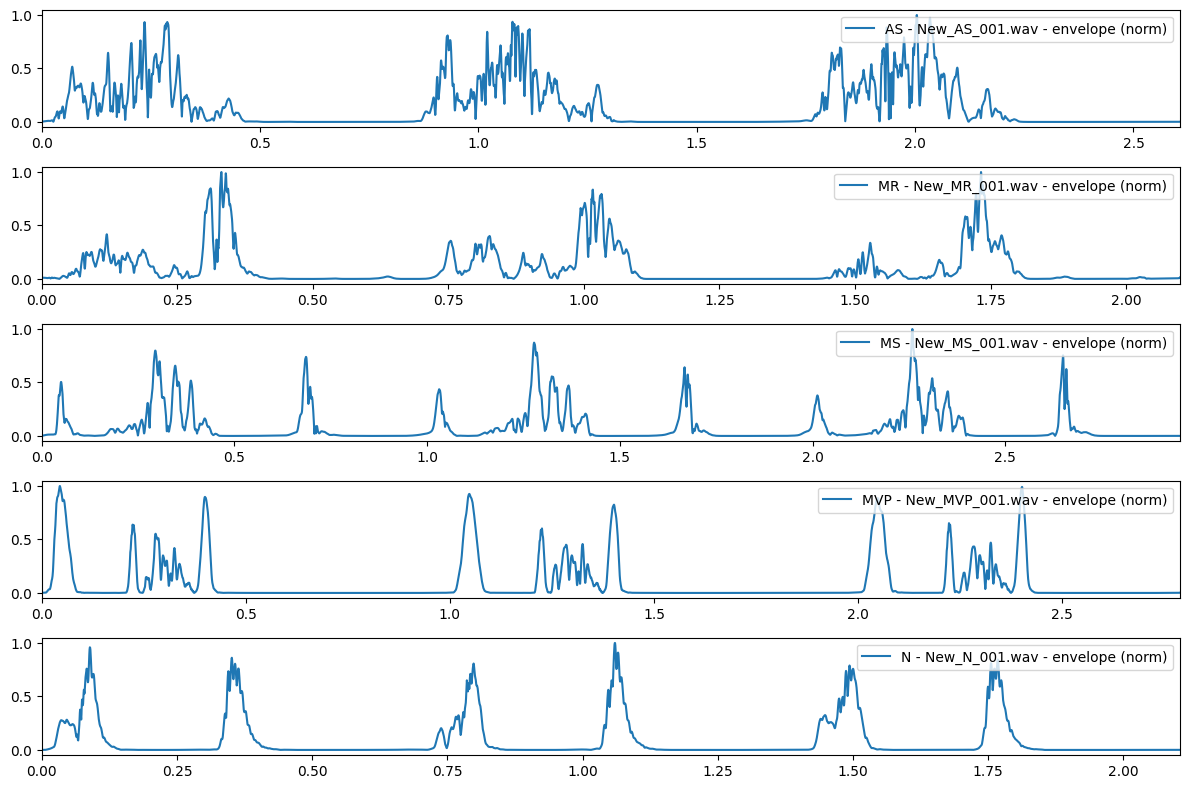


=== DONE: Semua sample per kelas sudah ditampilkan ===


In [47]:
# Blok 8 - overlay envelope untuk sample per kelas (WITH SAMPLE IDENTIFIER PRINTS)
import random
plt.figure(figsize=(12,8))

labels = ['AS','MR','MS','MVP','N']

print("====================================")
print("=== OVERLAY ENVELOPE PER KELAS ====")
print("====================================")

for i, lab in enumerate(labels, 1):
    folder = os.path.join("PCG/dataset", lab)
    files = [f for f in os.listdir(folder) if f.endswith('.wav')]

    if not files:
        print(f"[WARNING] Tidak ada file .wav di folder {lab}")
        continue

    # Pilih sample pertama (logika tetap)
    fn = files[0]

    # --- Tambahan Output Identitas ---
    print(f"\nKelas: {lab}")
    print(f"Sample file digunakan: {fn}")

    sig, sr = librosa.load(os.path.join(folder, fn), sr=None)
    sig, sr = ensure_sr(sig, sr, 2000)
    sig = wavelet_denoise(bandpass_filter(sig, sr))

    # amplitude envelope
    env = envelope_hilbert(sig)
    t = np.arange(len(env)) / sr

    plt.subplot(len(labels), 1, i)
    plt.plot(t, env / np.max(env), label=f"{lab} - {fn} - envelope (norm)")
    plt.xlim(0, min(3, t[-1]))  # show first 3s
    plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

print("\n=== DONE: Semua sample per kelas sudah ditampilkan ===")



COBA LOAD AUDIO:

PCG/
 └── dataset/
      ├── AS/
      ├── MR/
      ├── MS/
      ├── MVP/
      └── N/


In [2]:
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from scipy.signal import welch
from IPython.display import Audio


=== AS ===
Path file: PCG/dataset\AS\New_AS_001.wav


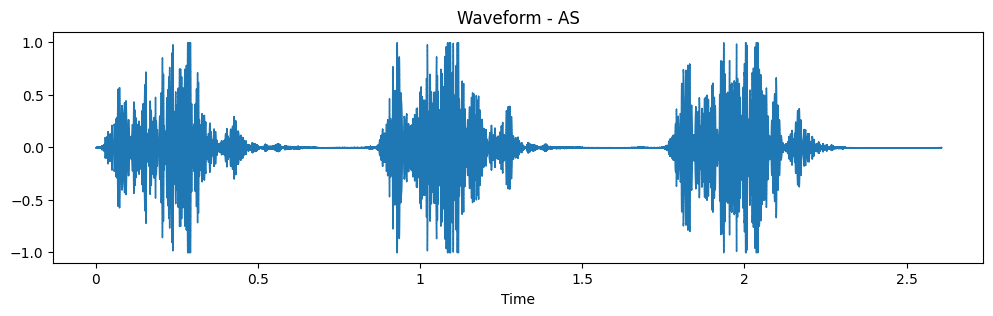

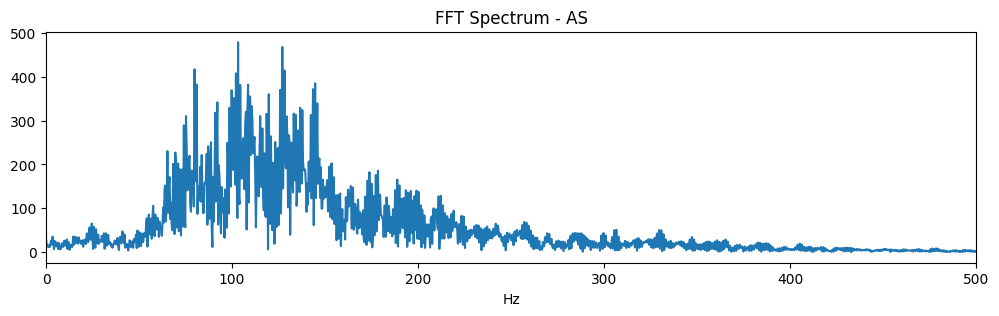

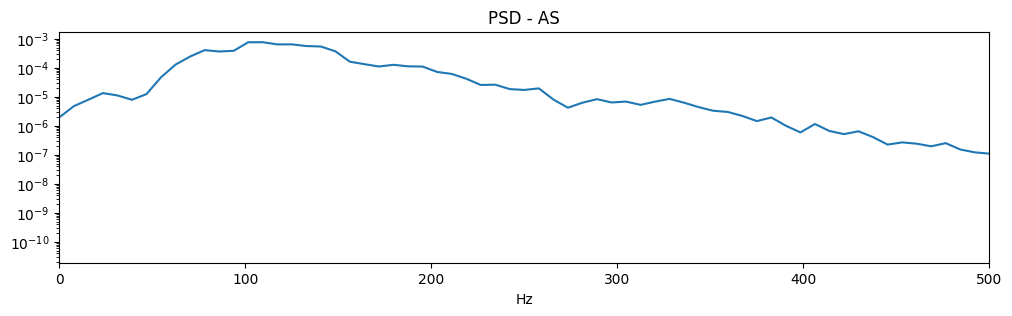

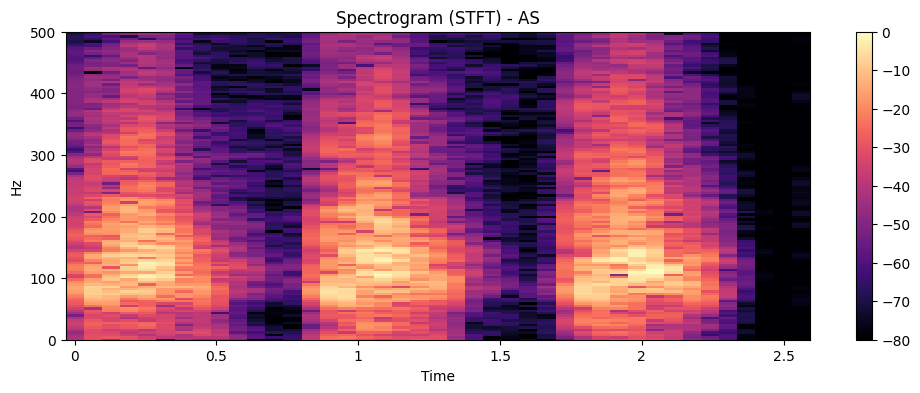

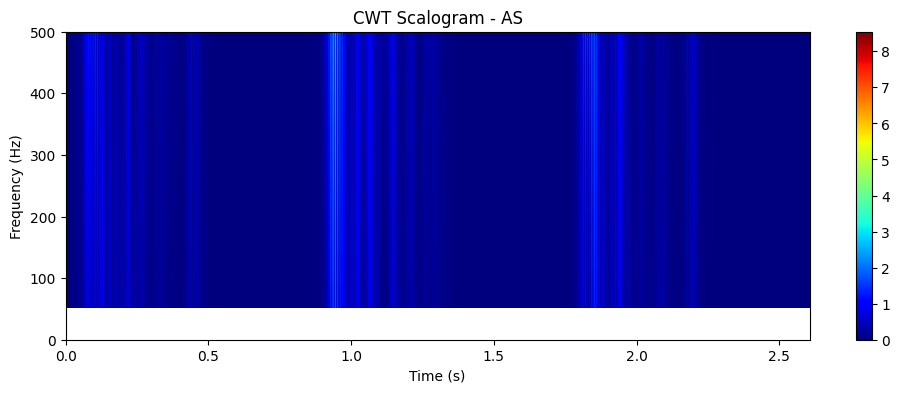

Playing audio:



=== MR ===
Path file: PCG/dataset\MR\New_MR_001.wav


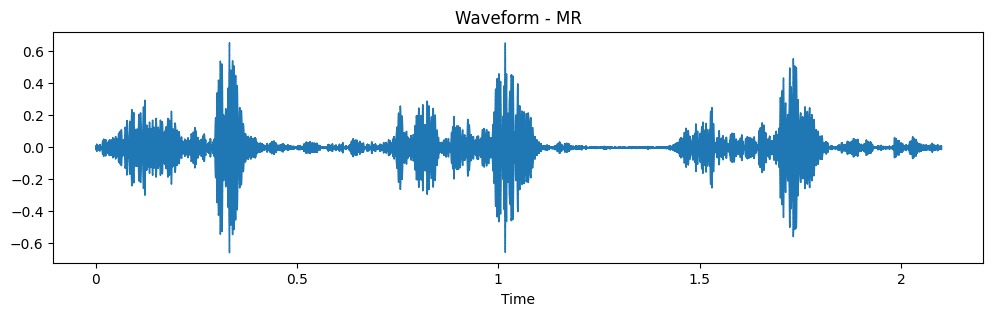

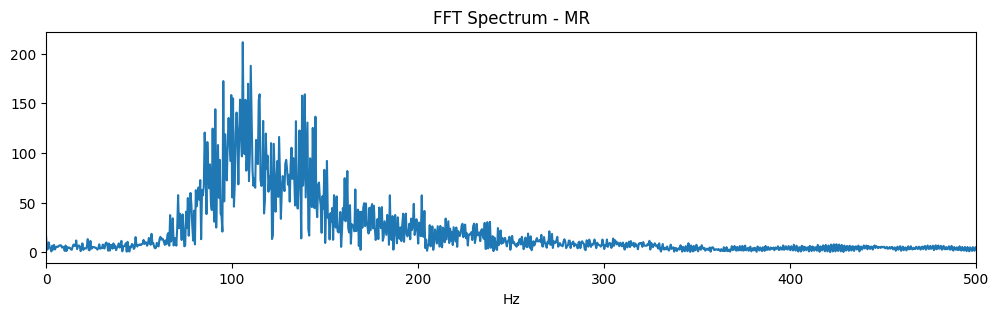

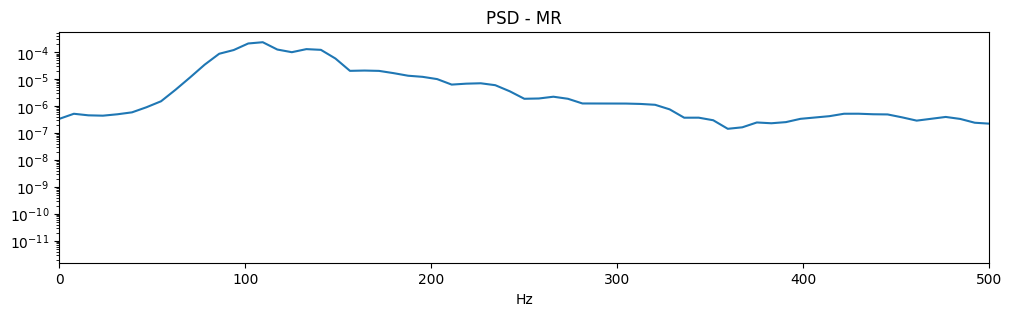

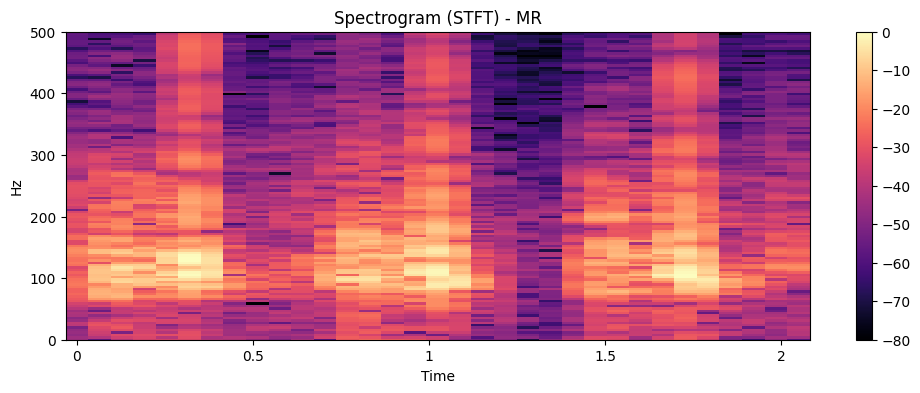

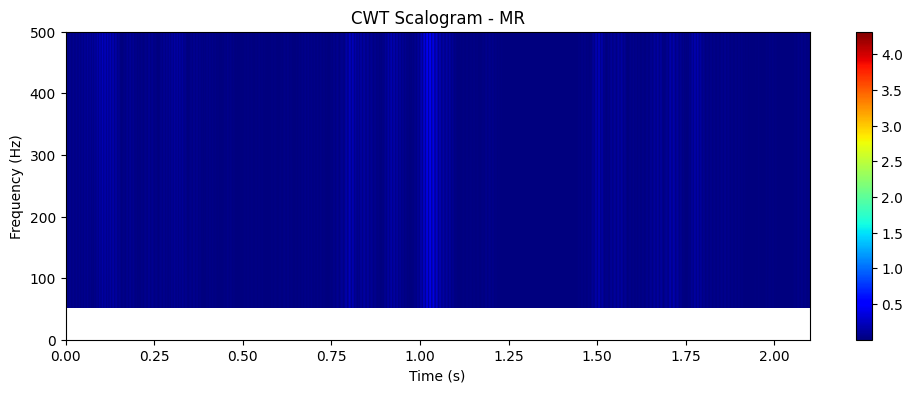

Playing audio:



=== MS ===
Path file: PCG/dataset\MS\New_MS_001.wav


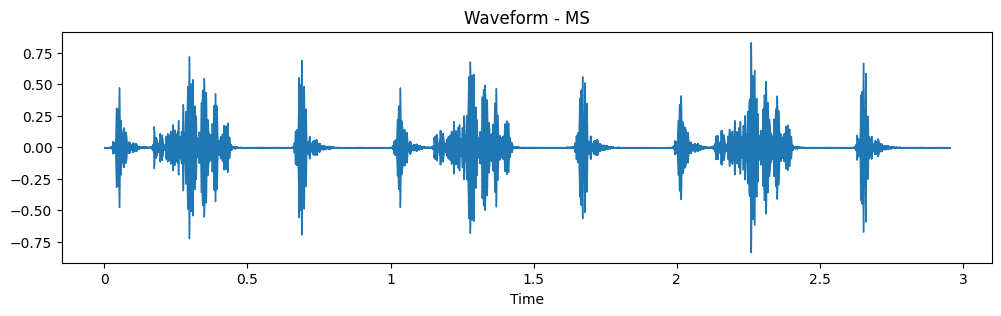

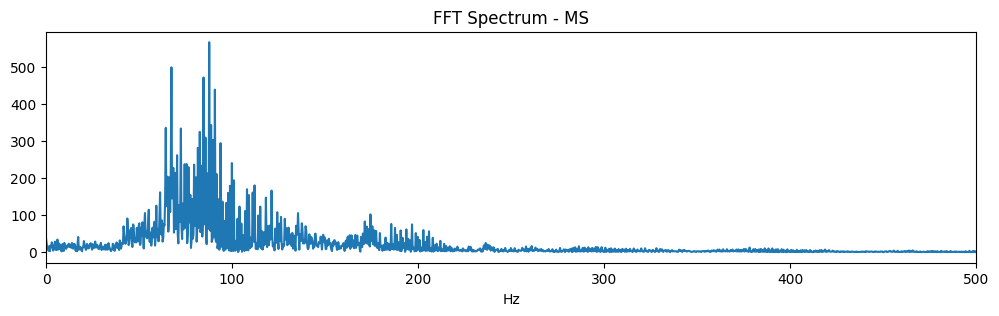

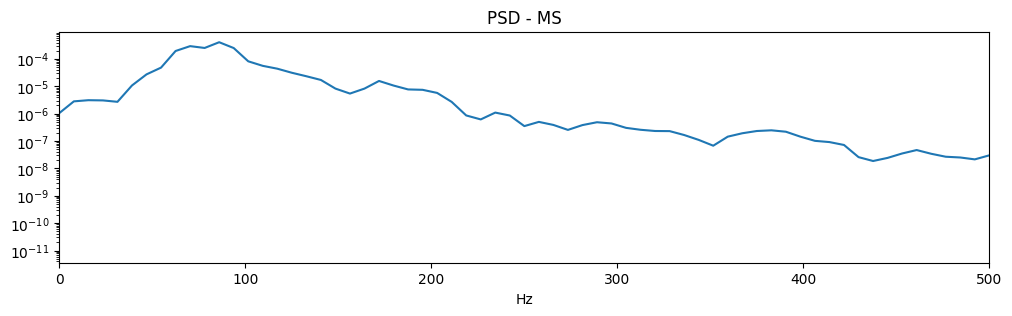

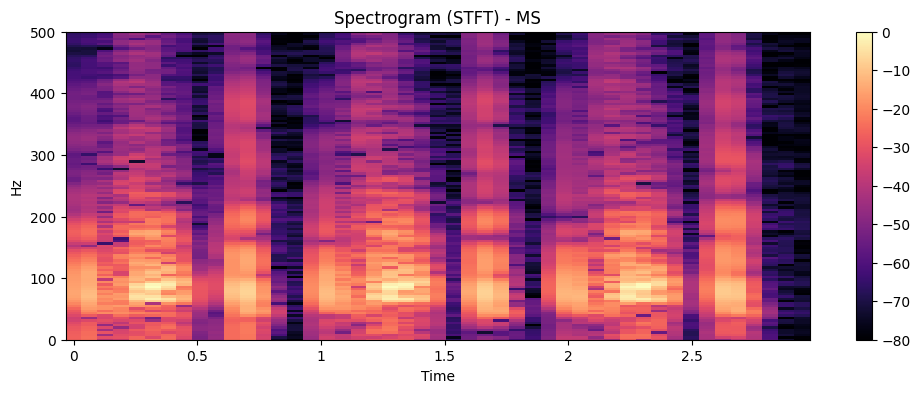

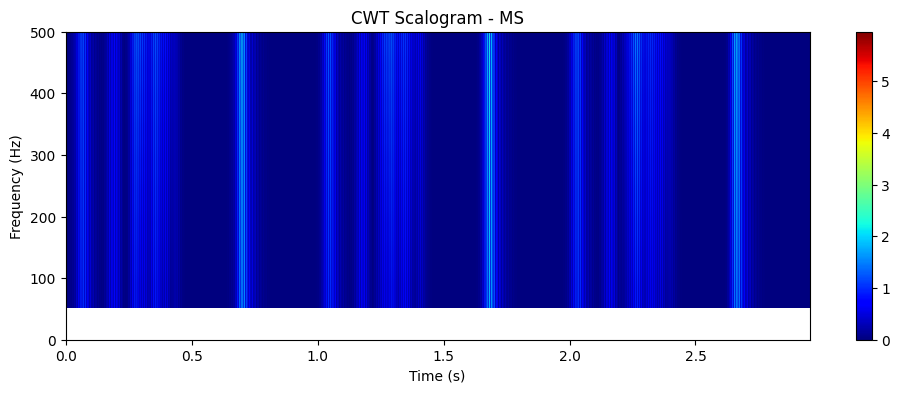

Playing audio:



=== MVP ===
Path file: PCG/dataset\MVP\New_MVP_001.wav


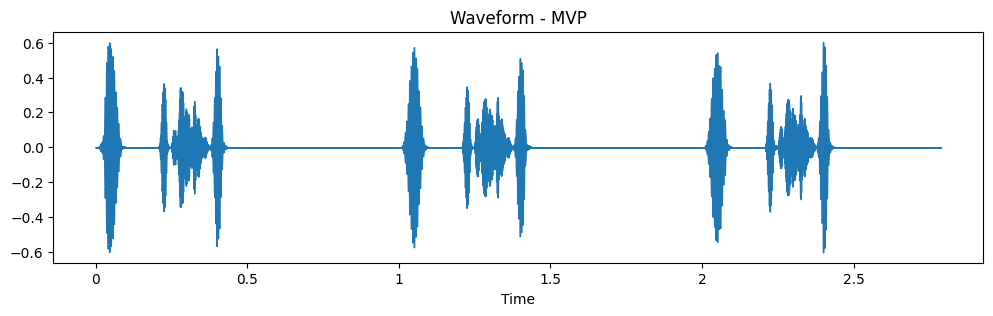

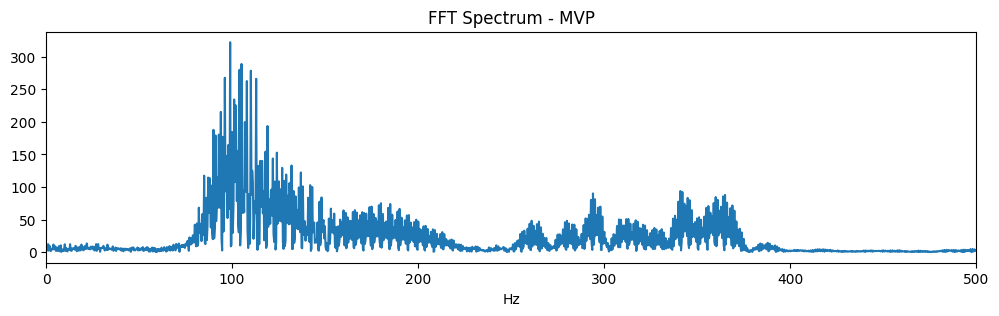

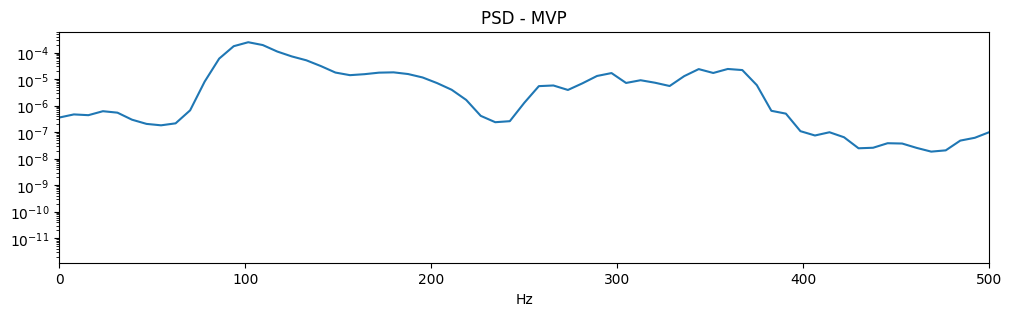

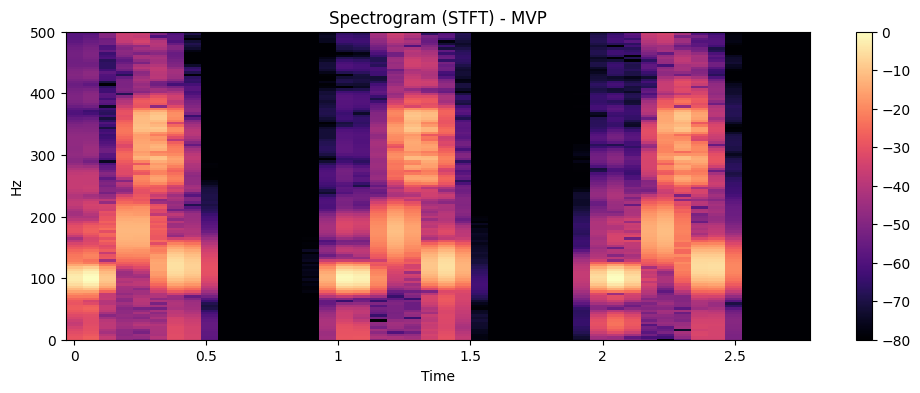

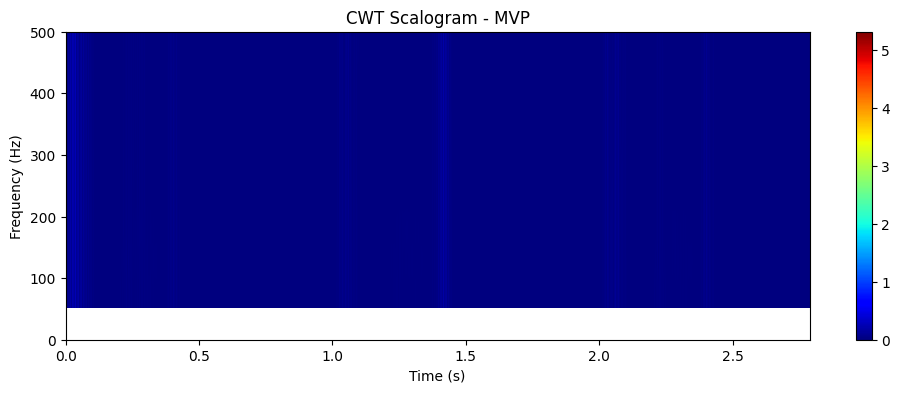

Playing audio:



=== N ===
Path file: PCG/dataset\N\New_N_001.wav


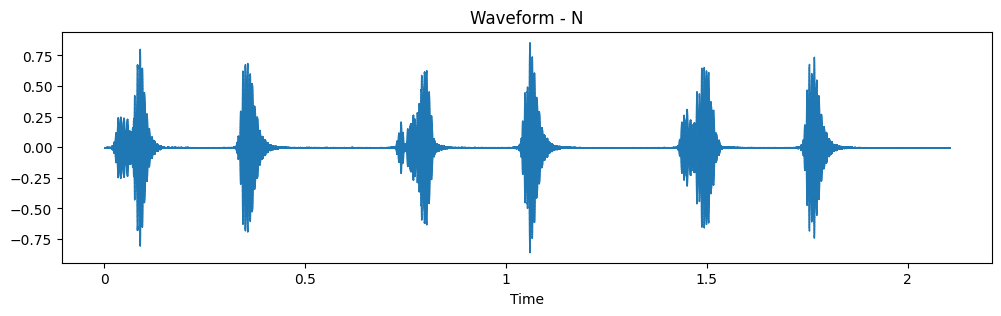

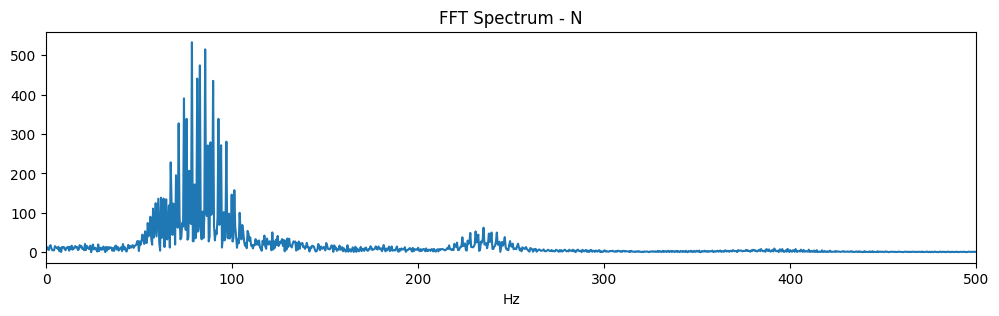

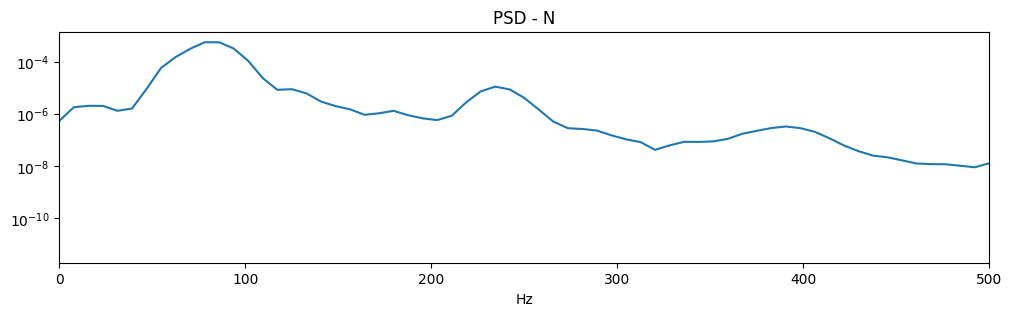

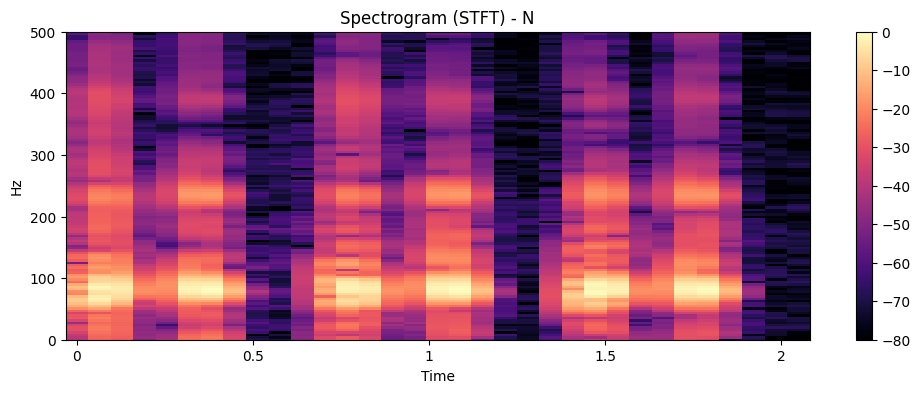

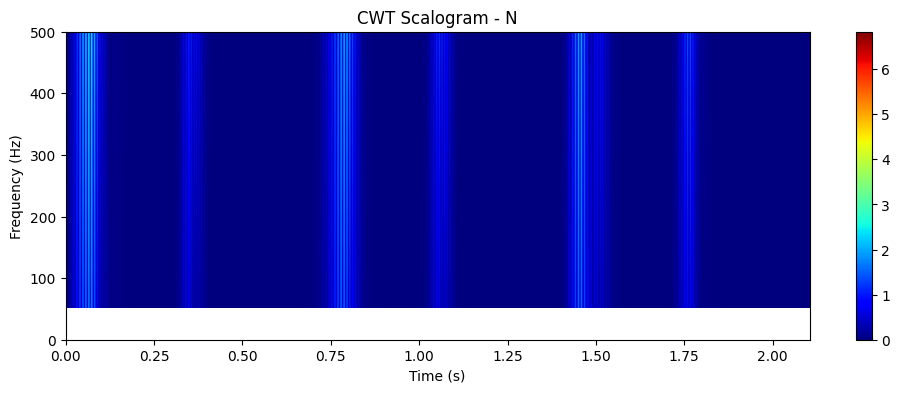

Playing audio:


In [24]:
def analyze_and_visualize(file_path, label):
    print(f"\n=== {label} ===")
    print("Path file:", file_path)

    y, sr = librosa.load(file_path, sr=None)

    # Insight: Waveform membantu melihat pola amplitudo, intensitas suara jantung, durasi siklus, dan mendeteksi anomali S1–S2.
    plt.figure(figsize=(12, 3))
    librosa.display.waveshow(y, sr=sr)
    plt.title(f"Waveform - {label}")
    plt.show()

    # Insight: FFT menunjukkan frekuensi dominan. Murmur biasanya tampak sebagai energi frekuensi rendah–menengah yang melebar.
    Y = np.abs(np.fft.rfft(y))
    freqs = np.fft.rfftfreq(len(y), 1/sr)

    plt.figure(figsize=(12, 3))
    plt.plot(freqs, Y)
    plt.title(f"FFT Spectrum - {label}")
    plt.xlim(0, 500)
    plt.xlabel("Hz")
    plt.show()

    # Insight: PSD (Welch) memberi estimasi energi rata-rata per frekuensi. Cocok untuk membedakan murmur AS, MR, MS, dll berdasarkan distribusi power.
    f_welch, Pxx = welch(y, fs=sr, nperseg=1024)

    plt.figure(figsize=(12, 3))
    plt.semilogy(f_welch, Pxx)
    plt.title(f"PSD - {label}")
    plt.xlim(0, 500)
    plt.xlabel("Hz")
    plt.show()

    # Insight: Spectrogram STFT menampilkan perubahan energi frekuensi terhadap waktu. S1 & S2 terlihat jelas, murmur tampak sebagai pola gelap yang memanjang.
    S = np.abs(librosa.stft(y))
    S_db = librosa.amplitude_to_db(S, ref=np.max)

    plt.figure(figsize=(12, 4))
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar()
    plt.title(f"Spectrogram (STFT) - {label}")
    plt.ylim(0, 500)
    plt.show()

    # Insight: CWT Scalogram (Wavelet) sangat baik untuk mendeteksi murmur transien/dinamis. Resolusi waktu lebih halus dibanding STFT.
    import pywt
    scales = np.arange(1, 128)
    cwtmatr, freqs_cwt = pywt.cwt(y, scales, 'morl', sampling_period=1/sr)

    plt.figure(figsize=(12, 4))
    plt.imshow(np.abs(cwtmatr), extent=[0, len(y)/sr, freqs_cwt[-1], freqs_cwt[0]],
               cmap='jet', aspect='auto')
    plt.title(f"CWT Scalogram - {label}")
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.ylim(0, 500)
    plt.colorbar()
    plt.show()

    print("Playing audio:")
    display(Audio(y, rate=sr))


DATA_DIR = "PCG/dataset"
labels = ["AS", "MR", "MS", "MVP", "N"]

for lbl in labels:
    folder = os.path.join(DATA_DIR, lbl)
    files = [f for f in os.listdir(folder) if f.endswith(".wav")]

    if len(files) == 0:
        print(f"Tidak ada file di folder {lbl}")
        continue

    file_path = os.path.join(folder, files[0])
    analyze_and_visualize(file_path, lbl)
